# 08 — DL Input Windows

Stage 09. Builds the windowed input sequences for the LSTM (`src/windows.py`) and
checks shapes, imputation, scaling and leakage. The target (PM2.5 at *t + 1*) and the
common eval set are unchanged from Phase 1, so the LSTM is later scored on exactly the
same hours as XGBoost. No model is trained here.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_raw, validate
from src import windows as W, features as F
from src import plot_style as ps

ps.apply()
df = load_raw(); validate(df)
X, y, split, mask, stats = W.build_sequence_dataset(df)
chans = W.build_channels(df).columns.tolist()
print('X:', X.shape, '| lookback:', W.LOOKBACK, 'h | channels:', X.shape[2])

X: (43801, 24, 14) | lookback: 24 h | channels: 14


## 1. Channels

The LSTM reads raw hourly history and learns the temporal structure itself, instead of
the hand-made lags and rolling windows of Stage 05. `pm25` is forward-filled with a
missing flag (it has gaps of up to 155 h); the weather channels have no gaps.

| Channel | Definition | Why |
|---|---|---|
| `pm25` | PM2.5 at each hour, forward-filled | the series being forecast |
| `pm25_missing` | 1 where `pm25` was imputed | lets the LSTM discount filled hours |
| `dewp`, `temp`, `pres` | weather at each hour | humidity, temperature, pressure context |
| `wind_speed` | hourly speed decoded from `wind_cum` | strongest weather signal (Stage 03) |
| `wind_{NE,NW,SE,cv}` | one-hot wind direction | direction, as four 0/1 channels |
| `snow_cum`, `rain_cum` | consecutive hours of snow / rain | wet deposition |
| `hour_sin`, `hour_cos` | cyclical hour of each step | daily rhythm inside the window |

In [2]:
pd.DataFrame({'channel': chans, 'standardised': [c in W.SCALE_CHANNELS for c in chans]})

,channel,standardised
0,pm25,True
1,pm25_missing,False
2,dewp,True
3,temp,True
4,pres,True
5,wind_speed,True
6,wind_NE,False
7,wind_NW,False
8,wind_SE,False
9,wind_cv,False


## 2. Shapes and the shared eval set

One window per issuance time with a full 24-hour history; the first 23 hours are dropped.
Samples are split by their target hour, exactly as in Phase 1. The common eval mask picks
the hours on which every model is scored, so the validation and test counts must match the
Phase 1 feature pipeline.

In [3]:
print('split sizes :', split.value_counts().reindex(['train', 'val', 'test']).to_dict())
print('eval hours  :', mask.groupby(split).sum().reindex(['train', 'val', 'test']).astype(int).to_dict())

_, _, split1, mask1 = F.build_dataset(df)          # Phase 1 pipeline, same raw data
same, split1 = mask1.reindex(mask.index), split1.reindex(mask.index)
for s in ['val', 'test']:
    n_lstm = int((mask & (split == s)).sum())
    n_ml = int((same & (split1 == s)).sum())
    print(f'{s}: LSTM {n_lstm} == Phase 1 {n_ml} ->', n_lstm == n_ml)
    assert n_lstm == n_ml

split sizes : {'train': 26280, 'val': 8760, 'test': 8760}
eval hours  : {'train': 23452, 'val': 8563, 'test': 8531}
val: LSTM 8563 == Phase 1 8563 -> True
test: LSTM 8531 == Phase 1 8531 -> True


## 3. Imputation and no missing values

An LSTM cannot read NaN. PM2.5 gaps are forward-filled and flagged; all other channels are
already complete (`src.data.validate`). The tensor therefore has no missing values.

In [4]:
print('NaN in X?', bool(np.isnan(X).any()))
assert not np.isnan(X).any()
print('imputed pm25 steps across all windows:', int(X[:, :, chans.index('pm25_missing')].sum()))

NaN in X? False
imputed pm25 steps across all windows: 49332


## 4. Scaling uses training statistics only

Continuous channels are standardised with 2010–2012 statistics; validation and test are
transformed with the same frozen numbers (no peeking). On the training rows the scaled
channels have mean ≈ 0 and standard deviation ≈ 1.

In [5]:
tr = (split == 'train').to_numpy()
last = X[:, -1, :]            # the pm(t) step of every window
chk = pd.DataFrame({'train_mean': last[tr].mean(0), 'train_std': last[tr].std(0)}, index=chans)
chk.loc[W.SCALE_CHANNELS].round(3)

,train_mean,train_std
pm25,0.000,1.000
dewp,0.001,1.000
temp,0.001,0.999
pres,-0.000,1.000
wind_speed,0.000,1.000
snow_cum,0.000,1.000
rain_cum,0.000,1.000


## 5. No future leakage

The window for issuance *t* ends at `pm(t)`; the target `pm(t + 1)` is strictly in the
future. Poisoning a future hour must leave every input window unchanged while changing only
the target.

In [6]:
i = np.where((split == 'test').to_numpy())[0][5000]
t = mask.index[i]; tpos = df.index.get_loc(t)

mu, sd = stats['pm25']
assert np.isclose(X[i, -1, chans.index('pm25')], (df['pm25'].ffill().iloc[tpos] - mu) / sd)

df2 = df.copy()
df2.iloc[tpos + 1, df2.columns.get_loc('pm25')] = 9999.0      # poison the future hour t+1
X2, y2, *_ = W.build_sequence_dataset(df2)
print('window unchanged after poisoning t+1 :', np.array_equal(X[i], X2[i]))
print('target reflects the future           :', y[i] != y2[i])
assert np.array_equal(X[i], X2[i]) and y[i] != y2[i]

window unchanged after poisoning t+1 : True
target reflects the future           : True


## 6. Example window

One input window: the PM2.5 channel over the 24 hours up to *t*, and the single value the
LSTM must predict at *t + 1*.

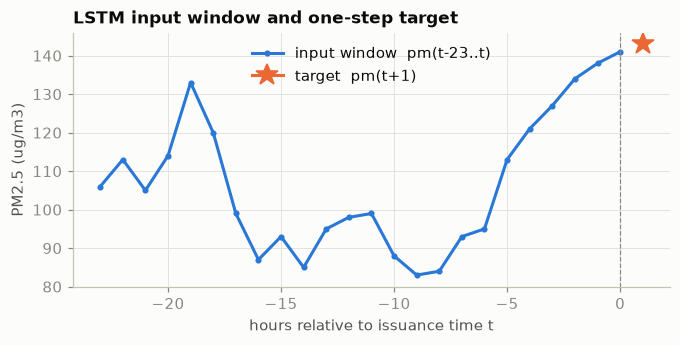

In [7]:
t = pd.Timestamp('2014-07-28 07:00'); tpos = df.index.get_loc(t)
hist = df['pm25'].ffill().iloc[tpos - W.LOOKBACK + 1: tpos + 1].to_numpy()
target = df['pm25'].iloc[tpos + 1]

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(-W.LOOKBACK + 1, 1), hist, color=ps.PRIMARY, marker='o', ms=3, label='input window  pm(t-23..t)')
ax.plot([1], [target], color=ps.SERIES[1], marker='*', ms=15, label='target  pm(t+1)')
ax.axvline(0, color=ps.MUTED, lw=0.8, ls='--')
ax.set_xlabel('hours relative to issuance time t'); ax.set_ylabel('PM2.5 (ug/m3)')
ax.set_title('LSTM input window and one-step target')
ax.legend()
ps.save(fig, 'dl_01_window_example')
plt.show()